# UTS II4013 Data Analytics
## Personalized Data Auditor & Decision Analyst

| | |
|---|---|
| **Nama** | Amudi Purba |
| **NIM** | 18223049 |
| **Kelas** | K01 |

---

## Pernyataan Keaslian

Saya menyatakan bahwa seluruh analisis pada notebook ini dikerjakan secara mandiri berdasarkan dataset yang dihasilkan dari NIM saya sendiri (18223049). Setiap keputusan analitik dijelaskan dengan alasan yang dapat saya pertanggungjawabkan. Penggunaan AI hanya terbatas pada bantuan sintaks kode dan referensi konsep, sebagaimana dicantumkan pada bagian Q.

## A. Tujuan Analisis

**1. Tujuan analisis:**  
Analisis ini bertujuan untuk memahami pola konsumsi energi gedung kampus berdasarkan faktor lingkungan (suhu, kelembapan) dan faktor aktivitas (jumlah mahasiswa, penggunaan perangkat). Model prediktif dibangun agar kampus dapat mengantisipasi kebutuhan daya secara lebih efisien dan mengidentifikasi periode konsumsi energi yang berpotensi dioptimasi.

**2. Target variabel:**  
`energy_consumption` — konsumsi energi gedung dalam satuan kWh. Variabel ini bersifat kontinu dan merupakan hasil akhir yang dipengaruhi oleh kombinasi faktor lingkungan dan perilaku pengguna gedung, sehingga cocok sebagai target regresi.

**3. Keputusan yang ingin didukung:**  
- Kapan jadwal operasional gedung dapat dikurangi untuk menghemat energi?
- Faktor mana (suhu, kepadatan, perangkat) yang paling berkontribusi terhadap lonjakan konsumsi energi?
- Apakah hari kerja dan akhir pekan memiliki pola konsumsi yang cukup berbeda untuk dijadikan dasar kebijakan operasional berbeda?

## B. Import Library

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

plt.rcParams["figure.figsize"] = (8, 5)

## C. Membuat Dataset Personal

In [ ]:
# Isi dengan NIM masing-masing
nim = "18223049"

In [ ]:
def generate_dataset(nim, n_samples=500):
    np.random.seed(int(nim[-3:]))

    noise_level = int(nim[1])       # digit ke-2
    missing_pattern = int(nim[3])   # digit ke-4
    bias_factor = int(nim[-1])      # digit terakhir

    timestamp = pd.date_range(start="2024-01-01", periods=n_samples, freq="h")

    temperature = 25 + 5 * np.sin(np.linspace(0, 10, n_samples)) + np.random.randn(n_samples)
    humidity = 60 + 10 * np.cos(np.linspace(0, 5, n_samples)) + np.random.randn(n_samples)

    student_count = np.random.randint(50, 500, n_samples)
    device_usage = student_count * np.random.uniform(0.5, 1.5, n_samples)

    day_type = np.where(pd.Series(timestamp).dt.dayofweek < 5, "weekday", "weekend")

    energy = (
        0.5 * temperature +
        0.3 * humidity +
        0.01 * student_count +
        0.02 * device_usage +
        bias_factor * 2
    )

    # Komponen non-linear
    energy += 5 * np.sin(student_count / 100)

    # Noise berdasarkan NIM
    energy += np.random.randn(n_samples) * noise_level

    df = pd.DataFrame({
        "timestamp": timestamp,
        "temperature": temperature,
        "humidity": humidity,
        "student_count": student_count,
        "device_usage": device_usage,
        "day_type": day_type,
        "energy_consumption": energy
    })

    # Inject missing values berdasarkan pola NIM
    if missing_pattern % 3 == 0:
        df.loc[df.sample(frac=0.1, random_state=1).index, "temperature"] = np.nan
    elif missing_pattern % 3 == 1:
        df.loc[df.sample(frac=0.1, random_state=1).index, "humidity"] = np.nan
    else:
        df.loc[df.sample(frac=0.1, random_state=1).index, "student_count"] = np.nan

    # Inject outliers pada target
    outlier_idx = np.random.choice(df.index, size=int(0.05 * n_samples), replace=False)
    df.loc[outlier_idx, "energy_consumption"] *= (1 + bias_factor / 5)

    return df

In [ ]:
df = generate_dataset(nim)
df.head()

,timestamp,temperature,humidity,student_count,device_usage,day_type,energy_consumption
0,2024-01-01 00:00:00,23.956841,70.845470,96.0,90.439075,weekday,49.276601
1,2024-01-01 01:00:00,24.279338,71.399579,434.0,390.324787,weekday,58.332588
2,2024-01-01 02:00:00,25.865493,70.647052,224.0,219.040120,weekday,67.725912
3,2024-01-01 03:00:00,27.123047,71.053314,200.0,136.810001,weekday,64.502765
4,2024-01-01 04:00:00,23.958789,69.920492,NaN,126.736057,weekday,57.166208


In [ ]:
df.shape

(500, 7)

In [ ]:
# Simpan dataset personal agar mudah dilampirkan saat pengumpulan
output_csv = f"dataset_UTS_{nim}.csv"
df.to_csv(output_csv, index=False)
print(f"Dataset tersimpan sebagai: {output_csv}")

Dataset tersimpan sebagai: dataset_UTS_18223049.csv


## D. Data Understanding

Lakukan pemeriksaan awal terhadap dataset:
1. Ukuran data
2. Nama variabel
3. Tipe data
4. Ringkasan statistik
5. Dugaan awal masalah kualitas data

**Tulis interpretasi Anda setelah kode dijalankan.**
1. Ukuran Data
- Dataset terdiri dari:
- 500 baris data
- 7 variabel\
Jumlah data cukup untuk melakukan analisis eksploratif dan pemodelan regresi.

2. Nama Variabel\
 Variabel yang tersedia pada dataset:
- timestamp : waktu pengamatan data
- temperature : suhu lingkungan
- humidity : tingkat kelembapan udara
- student_count : jumlah mahasiswa
- device_usage : tingkat penggunaan perangkat elektronik
- day_type : tipe hari (weekday/weekend)
- energy_consumption : konsumsi energi (variabel target)

3. Tipe Data\
Berdasarkan pemeriksaan tipe data:
- timestamp : datetime
- temperature, humidity, student_count, device_usage, energy_consumption : numerik
- day_type : kategorikal\
Tipe data telah sesuai dengan karakteristik masing-masing variabel.

4. Ringkasan Statistik\
Statistik deskriptif menunjukkan bahwa:
- Rata-rata konsumsi energi sekitar 61.52 dengan variasi yang cukup tinggi.
- Nilai maksimum konsumsi energi jauh lebih besar dibanding median, yang mengindikasikan kemungkinan adanya nilai ekstrem.
- Jumlah mahasiswa memiliki rentang nilai luas, menunjukkan variasi aktivitas kampus yang signifikan.

5. Dugaan Awal Masalah Kualitas Data\
a. Missing Value\
Ditemukan 50 nilai hilang pada variabel student_count (±10% data), sehingga diperlukan metode imputasi pada tahap preprocessing.\
b. Outliers\
Nilai maksimum energy_consumption sangat tinggi dibandingkan distribusi utama data, sehingga terdapat indikasi outlier yang dapat mempengaruhi model regresi.\
c. Distribusi dan Non-Linearitas\
Hubungan antar variabel diperkirakan tidak sepenuhnya linear karena konsumsi energi dipengaruhi kombinasi faktor lingkungan dan aktivitas manusia.\
d. Potensi Multikolinearitas\
Variabel device_usage berkaitan erat dengan student_count, sehingga berpotensi menghasilkan korelasi tinggi antar fitur yang perlu diperiksa lebih lanjut.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   timestamp           500 non-null    datetime64[ns]
 1   temperature         500 non-null    float64       
 2   humidity            500 non-null    float64       
 3   student_count       450 non-null    float64       
 4   device_usage        500 non-null    float64       
 5   day_type            500 non-null    object        
 6   energy_consumption  500 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 27.5+ KB


In [ ]:
df.describe(include="all")

,timestamp,temperature,humidity,student_count,device_usage,day_type,energy_consumption
count,500,500.000000,500.000000,450.000000,500.000000,500,500.000000
unique,NaN,NaN,NaN,NaN,NaN,2,NaN
top,NaN,NaN,NaN,NaN,NaN,weekday,NaN
freq,NaN,NaN,NaN,NaN,NaN,360,NaN
mean,2024-01-11 09:30:00,25.895343,58.138242,278.673333,274.925337,NaN,61.521788
min,2024-01-01 00:00:00,17.537968,48.525449,51.000000,38.400870,NaN,26.731067
25%,2024-01-06 04:45:00,23.096723,51.929463,171.000000,150.219020,NaN,50.276124
50%,2024-01-11 09:30:00,26.442011,56.667656,277.000000,256.787676,NaN,56.877286
75%,2024-01-16 14:15:00,28.793300,63.370167,395.250000,374.973539,NaN,63.533108
max,2024-01-21 19:00:00,32.076273,72.018859,499.000000,721.059460,NaN,193.693439


In [ ]:
df.isna().sum()

,0
timestamp,0
temperature,0
humidity,0
student_count,50
device_usage,0
day_type,0
energy_consumption,0


### Interpretasi Awal
Jawab pertanyaan berikut:
- Variabel mana yang numerik dan kategorikal?
- Apakah ada missing value?
- Apakah ada nilai yang tampak tidak wajar?
- Apakah target variabel tampak cocok untuk regresi?

**Tulis jawaban Anda di sini**

**Variabel numerik dan kategorikal:**  
- Dataset terdiri dari **5 variabel numerik**, yaitu temperature, humidity, student_count, device_usage, energy_consumption.
- Terdapat **1 variabel kategorikal** yaitu day_type bernilai weekday/weekend.
Kolom timestamp bertipe datetime dan berfungsi sebagai penanda waktu; variabel ini belum langsung digunakan sebagai fitur prediktif tetapi dapat diturunkan menjadi fitur tambahan seperti jam atau hari.


**Missing value:**  
Terdapat **50 missing values (10%) pada student_count** sedangkan pada variabel lain lengkap. student_count merepresentasikan tingkat aktivitas mahasiswa yang kemungkinan berpengaruh langsung terhadap konsumsi energi, maka penanganan ini harus dilakukan secara hati-hati agar tidak mengubah distribusi data maupun hubungan antar variabel.

**Nilai yang tampak tidak wajar:**  
Dari `df.describe()`, nilai maksimum energy_consumption mencapai sekitar **193 kWh**, jauh di atas median, ~63 kWh.Hal ini mengindikasikan adanya outlier ekstrem pada variabel target. Outlier seperti ini berpotensi:
- meningkatkan error model regresi,
- mempengaruhi estimasi koefisien,
- serta menyebabkan model terlalu mengikuti nilai ekstrem.

**Kesesuaian target untuk regresi:**  
Variabel energy_consumption bersifat kontinu sehingga sesuai digunakan sebagai target regresi. Secara konseptual, konsumsi energi dipengaruhi oleh faktor lingkungan dan aktivitas pengguna gedung. Namun, variasi nilai yang cukup besar serta kemungkinan hubungan non-linear antar variabel menunjukkan bahwa regresi linear sebaiknya diperlakukan sebagai model baseline, dan evaluasi hasil model perlu dilakukan secara kritis.

## E. Audit Kualitas Data

Lakukan audit terhadap:
1. Missing values
2. Outliers
3. Ketidakkonsistenan format / tipe data
4. Potensi bias

In [ ]:
# Persentase missing value
missing_percent = df.isna().mean() * 100
missing_percent.sort_values(ascending=False)

,0
student_count,10.0
temperature,0.0
timestamp,0.0
humidity,0.0
device_usage,0.0
day_type,0.0
energy_consumption,0.0


In [ ]:
def detect_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return mask.sum(), lower, upper, mask

outlier_summary = []
for col in ["temperature", "humidity", "student_count", "device_usage", "energy_consumption"]:
    count, lower, upper, mask = detect_outliers_iqr(df[col].dropna())
    outlier_summary.append({
        "column": col,
        "outlier_count": int(count),
        "lower_bound": float(lower),
        "upper_bound": float(upper)
    })

pd.DataFrame(outlier_summary)

,column,outlier_count,lower_bound,upper_bound
0,temperature,0,14.551859,37.338164
1,humidity,0,34.768406,80.531223
2,student_count,0,-165.375000,731.625000
3,device_usage,1,-186.912758,712.105318
4,energy_consumption,26,30.390650,83.418583


### Hasil Audit

**Variabel bermasalah:**  
1. student_count: memiliki missing value sebesar 10% (50 dari 500 observasi).
2. energy_consumption: terdeteksi 26 outlier (≈5% data) dengan nilai melebihi batas atas IQR (83.42 kWh).
3. device_usage: terdapat 1 outlier namun jumlahnya sangat kecil sehingga dampaknya diperkirakan minimal.

**Jenis masalah:**  
1. Missing Value pada Variabel Aktivitas\
Kehilangan data terjadi pada student_count, yaitu variabel yang merepresentasikan kepadatan aktivitas mahasiswa. Karena variabel ini secara logis berkaitan langsung dengan penggunaan energi, missing value berpotensi mempengaruhi hubungan antar variabel apabila tidak ditangani dengan tepat.
2. Outlier Ekstrem pada Variabel Target\
Distribusi energy_consumption menunjukkan sebagian kecil nilai yang jauh lebih tinggi dibandingkan mayoritas data. Nilai ekstrem ini dapat merepresentasikan kondisi penggunaan energi yang tidak biasa, seperti lonjakan aktivitas gedung atau anomali operasional.
3. Konsistensi Struktur Data\
Seluruh kolom memiliki tipe data yang sesuai sehingga tidak ditemukan masalah format atau inkonsistensi skema data.

**Dampak potensial terhadap analisis:**  
1. Missing value pada student_count dapat menyebabkan hilangnya informasi aktivitas kampus dan berpotensi menimbulkan bias jika observasi langsung dihapus. Oleh karena itu diperlukan strategi imputasi yang mempertahankan pola distribusi data.
2. Outlier pada energy_consumption berpotensi meningkatkan nilai error dan membuat model regresi terlalu sensitif terhadap observasi ekstrem. Penanganan outlier perlu dipertimbangkan sebelum pemodelan dilakukan.
3. Perbedaan karakteristik kualitas data antar variabel menunjukkan bahwa tahap preprocessing (imputasi dan penanganan outlier) akan menjadi faktor kunci dalam memperoleh model yang stabil dan representatif.

## F. Penanganan Missing Value
Pilih satu metode imputasi yang menurut Anda paling tepat, misalnya:
- Mean
- Median
- Interpolation
- Metode lain

Jangan hanya menjalankan metode. Jelaskan:
1. Mengapa metode itu dipilih?
2. Mengapa metode lain tidak dipilih?

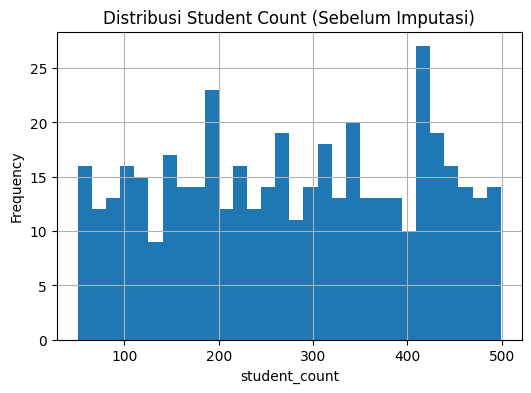

In [ ]:
plt.figure(figsize=(6,4))
df["student_count"].hist(bins=30)
plt.title("Distribusi Student Count (Sebelum Imputasi)")
plt.xlabel("student_count")
plt.ylabel("Frequency")
plt.show()

In [ ]:
df_median = df.copy()

median_value = df_median["student_count"].median()
df_median["student_count"] = df_median["student_count"].fillna(median_value)

df_median.isna().sum()

,0
timestamp,0
temperature,0
humidity,0
student_count,0
device_usage,0
day_type,0
energy_consumption,0


In [ ]:
df_mean = df.copy()

mean_value = df_mean["student_count"].mean()
df_mean["student_count"] = df_mean["student_count"].fillna(mean_value)

df_mean.isna().sum()

,0
timestamp,0
temperature,0
humidity,0
student_count,0
device_usage,0
day_type,0
energy_consumption,0


In [ ]:
comparison = pd.DataFrame({
    "Before Imputation": [
        df["student_count"].mean(),
        df["student_count"].median(),
        df["student_count"].std()
    ],
    "Mean Imputation": [
        df_mean["student_count"].mean(),
        df_mean["student_count"].median(),
        df_mean["student_count"].std()
    ],
    "Median Imputation": [
        df_median["student_count"].mean(),
        df_median["student_count"].median(),
        df_median["student_count"].std()
    ]
}, index=["Mean", "Median", "Std"])

comparison

,Before Imputation,Mean Imputation,Median Imputation
Mean,278.673333,278.673333,278.506000
Median,277.000000,278.673333,277.000000
Std,128.902174,122.273724,122.274757


In [ ]:
df_clean = df_median.copy()

### Justifikasi Missing Value Handling

Metode yang dipilih: Imputasi Median

---

**Mengapa metode Median dipilih?**\
Berdasarkan distribusi student_count, data tersebar cukup lebar pada rentang 50–500 mahasiswa dan tidak sepenuhnya simetris. Variabel ini juga merepresentasikan jumlah individu sehingga secara alami memiliki variasi tinggi dan berpotensi mengandung nilai ekstrem.

Hasil perbandingan statistik menunjukkan:
- Mean sebelum imputasi: 278.67
- Mean setelah median imputation: 278.51 (perubahan sangat kecil)
- Median tetap 277, sehingga pusat distribusi tidak bergeser
- Standar deviasi hanya sedikit menurun, menandakan variasi data tetap terjaga

Median dipilih karena:
- lebih robust terhadap outlier dibanding mean,
- mampu mempertahankan pusat distribusi asli data,
- tidak menarik distribusi ke arah nilai ekstrem.

Dengan demikian, imputasi tetap menjaga karakter dataset sekaligus mengisi nilai hilang secara stabil.

**Mengapa metode lain tidak dipilih?**\
1. Mean Imputation\
Mean imputation menghasilkan nilai mean yang identik dengan rata-rata awal, namun median berubah menjadi 278.67. Hal ini menunjukkan distribusi data sedikit bergeser menuju rata-rata, sehingga berpotensi mengurangi representasi kondisi aktivitas mahasiswa yang sebenarnya. Metode ini lebih sensitif terhadap nilai ekstrem.

2. Interpolation\
Interpolation umumnya digunakan pada data time series yang memiliki pola kontinuitas temporal yang kuat. Pada variabel student_count, tidak ada jaminan bahwa jumlah mahasiswa pada satu jam selalu berubah secara gradual terhadap jam sebelumnya, sehingga interpolasi dapat menghasilkan nilai yang tidak realistis.

3. Penghapusan Baris (Drop Missing Data)\
Menghapus data akan mengurangi sekitar 10% observasi, yang dapat menurunkan jumlah informasi dan berpotensi menimbulkan bias analisis.


## G. Outlier Handling dan Transformasi

Tentukan apakah outlier:

- Dipertahankan
- Dibatasi
- Dihapus
- Ditangani dengan model robust

Lalu tentukan apakah data perlu scaling atau transformasi.

In [ ]:
# Winsorization sederhana pada target
q1 = df_clean["energy_consumption"].quantile(0.25)
q3 = df_clean["energy_consumption"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

df_clean["energy_capped"] = df_clean["energy_consumption"].clip(lower=lower, upper=upper)
df_clean["target"] = df_clean["energy_capped"]

print("Lower bound:", lower)
print("Upper bound:", upper)

Lower bound: 30.390649604961116
Upper bound: 83.41858262648395


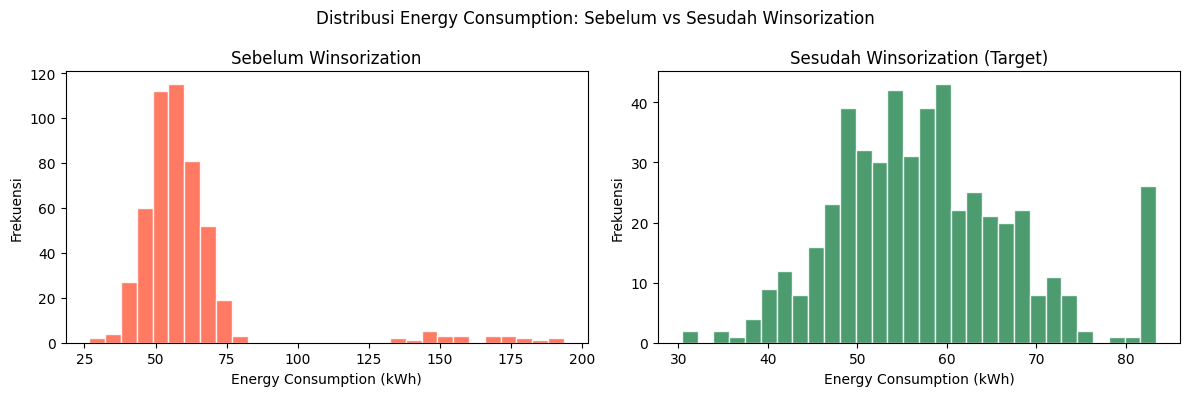

Jumlah nilai yang di-cap: 26 (5.2%)

Statistik target setelah winsorization:
count    500.000
mean      57.671
std       10.349
min       30.391
25%       50.276
50%       56.877
75%       63.533
max       83.419
Name: target, dtype: float64


In [ ]:
# Visualisasi efek winsorization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean["energy_consumption"], bins=30, color="tomato", edgecolor="white", alpha=0.85)
axes[0].set_title("Sebelum Winsorization")
axes[0].set_xlabel("Energy Consumption (kWh)")
axes[0].set_ylabel("Frekuensi")

axes[1].hist(df_clean["target"], bins=30, color="seagreen", edgecolor="white", alpha=0.85)
axes[1].set_title("Sesudah Winsorization (Target)")
axes[1].set_xlabel("Energy Consumption (kWh)")
axes[1].set_ylabel("Frekuensi")
plt.suptitle("Distribusi Energy Consumption: Sebelum vs Sesudah Winsorization")
plt.tight_layout()
plt.show()

n_capped = ((df_clean["energy_consumption"] > upper) | (df_clean["energy_consumption"] < lower)).sum()
print(f"Jumlah nilai yang di-cap: {n_capped} ({n_capped/500*100:.1f}%)")
print("\nStatistik target setelah winsorization:")
print(df_clean["target"].describe().round(3))

### Justifikasi Outlier dan Transformasi

**Keputusan: Outlier dibatasi (Winsorization/Capping)**

Outlier pada variabel target energy_consumption tidak dihapus, tetapi dibatasi menggunakan teknik Winsorization. Nilai ekstrem di luar batas IQR (30.39 – 83.42 kWh) di-cap ke batas minimum atau maksimum yang masih dianggap wajar. Tidak dihapus karena menghapus 26 baris berarti membuang informasi valid dari kolom lain pada baris yang sama. Outlier di sini hanya ada pada variabel **target**, bukan fitur, sehingga fitur-fitur seperti temperature, humidity, dll tetap valid dan berguna.

**Mengapa menggunakan Winsorization?**  
Pada kasus regresi konsumsi energi, nilai ekstrem tidak selalu merupakan kesalahan data. Konsumsi energi yang sangat tinggi masih mungkin terjadi akibat:
-lonjakan aktivitas mahasiswa,
-penggunaan perangkat secara intensif,
-kondisi operasional tertentu.


Menghapus data tersebut berisiko:
-menghilangkan informasi penting,
- mengurangi variasi nyata data,
- menyebabkan model kehilangan kemampuan mempelajari kondisi ekstrem.

Oleh karena itu, Winsorization dipilih karena:
- mempertahankan seluruh observasi,
- mengurangi pengaruh nilai ekstrem terhadap distribusi,
- menjaga stabilitas statistik tanpa merusak pola data.

**Dampak terhadap model:**  
Sebelum Winsorization, distribusi target menunjukkan right-skewed akibat beberapa nilai energi yang sangat tinggi. Kondisi ini dapat menyebabkan:

- koefisien regresi menjadi bias,
- model terlalu dipengaruhi sedikit data ekstrem,
- peningkatan error prediksi (terutama MSE/RMSE).

Setelah Winsorization:
- distribusi target menjadi lebih stabil,
- standar deviasi menurun,
- model regresi menjadi lebih robust dan generalizable,
- proses training lebih konvergen dan tidak didominasi outlier.

Dengan demikian, Winsorization membantu model untuk mempelajari pola tanpa kehilangan informasi penting.

**Apakah data perlu scaling atau transformasi?**  
Ya, karena model regresi sensitif terhadap perbedaan skala fitur. Terutama variabel seperti temperature, humidity, student_count, device_usage yang memiliki rentang nilai berbeda menyebabkan bobot model tidak seimbang.

## H. Visualisasi Data

Buat minimal:
1. Histogram target
2. Scatter plot fitur vs target
3. Visualisasi hubungan dua fitur

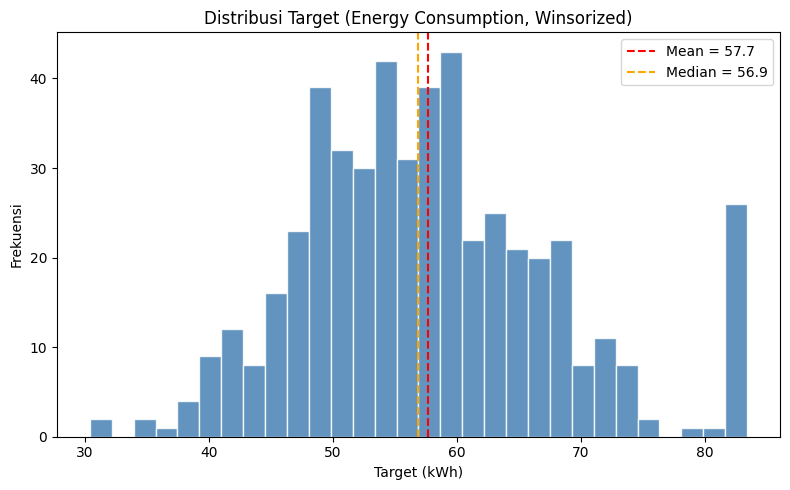

In [ ]:
# 1. Histogram target
plt.hist(df_clean["target"], bins=30, color="steelblue", edgecolor="white", alpha=0.85)
plt.axvline(df_clean["target"].mean(),   color="red",    linestyle="--", linewidth=1.5, label=f'Mean = {df_clean["target"].mean():.1f}')
plt.axvline(df_clean["target"].median(), color="orange", linestyle="--", linewidth=1.5, label=f'Median = {df_clean["target"].median():.1f}')
plt.title("Distribusi Target (Energy Consumption, Winsorized)")
plt.xlabel("Target (kWh)")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()
plt.show()

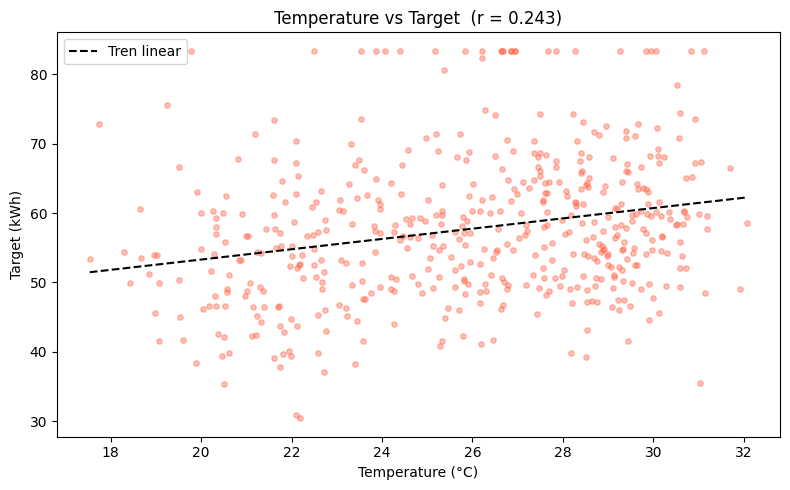

In [ ]:
# 2. Scatter plot fitur vs target
plt.scatter(df_clean["temperature"], df_clean["target"], alpha=0.4, s=15, color="tomato")
m = np.polyfit(df_clean["temperature"], df_clean["target"], 1)
xline = np.linspace(df_clean["temperature"].min(), df_clean["temperature"].max(), 100)
plt.plot(xline, np.polyval(m, xline), color="black", linewidth=1.5, linestyle="--", label="Tren linear")
r_temp = df_clean[["temperature","target"]].corr().iloc[0,1]
plt.title(f"Temperature vs Target  (r = {r_temp:.3f})")
plt.xlabel("Temperature (°C)")
plt.ylabel("Target (kWh)")
plt.legend()
plt.tight_layout()
plt.show()

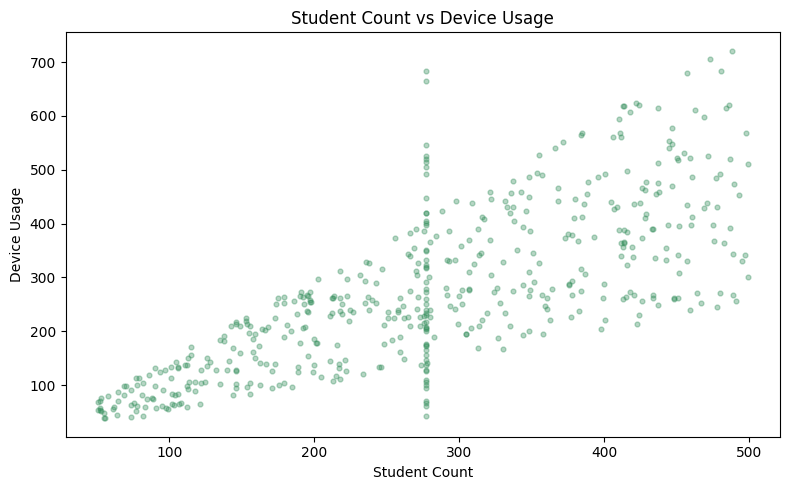

In [ ]:
# 3. Scatter: student_count vs device_usage (hubungan dua fitur)
plt.scatter(df_clean["student_count"], df_clean["device_usage"], alpha=0.35, s=12, color="seagreen")
plt.title("Student Count vs Device Usage")
plt.xlabel("Student Count")
plt.ylabel("Device Usage")
plt.tight_layout()
plt.show()

### Interpretasi Visualisasi

**Apakah distribusi target simetris, skewed, atau memiliki ekor panjang?**  
Distribusi target (energy consumption) terlihat mendekati simetris (approximately normal), namun terdapat sedikit skew ke kanan (positively skewed).

Hal ini terlihat dari:
- Mean (57.7) sedikit lebih besar dari median (56.9), indikasi skew ke kanan.
- Terdapat beberapa nilai tinggi (sekitar 75–83 kWh) yang membentuk ekor kanan (long tail ringan).
- Winsorization berhasil mengurangi ekstrem, tetapi masih menyisakan variasi alami data.

Distribusi hampir normal tetapi sedikit right-skewed dengan ekor kanan ringan, sehingga masih cukup cocok untuk model linear, namun perlu kewaspadaan terhadap nilai tinggi.

**Fitur mana yang tampak memiliki hubungan kuat dengan target?**  
Dari visualisasi:

- Temperature vs Target (r = 0.243):\
-> Korelasi positif lemah\
-> Scatter cukup menyebar,  hubungan tidak kuat\
-> Temperature bukan prediktor utama
- Student Count vs Device Usage (indikasi tidak langsung ke target)\
-> Terlihat hubungan positif yang cukup kuat\
-> Semakin banyak mahasiswa artinya penggunaan device meningkat signifikan

Ini mengindikasikan adanya hubungan tidak langsung antara Student Count -> Device Usage -> Energy Consumption.

Tidak ada hubungan kuat langsung ke target dari temperature. Selain itu, student activity (Student Count / Device Usage) lebih berpotensi kuat mempengaruhi target.

**Apakah ada pola non-linear?**  
Grafik menunjukkan adanya indikasi pola non-linear dalam hubungan antar variabel, khususnya pada hubungan antara temperature dan konsumsi energi. Meskipun terdapat tren linear yang meningkat, penyebaran data tidak merata dan menunjukkan variasi yang cukup besar pada rentang suhu tertentu, sehingga kenaikan suhu tidak selalu diikuti peningkatan konsumsi energi secara konsisten. Selain itu, pada hubungan antara student count dan device usage, terlihat bahwa meskipun tren umum meningkat, terdapat penyimpangan yang cukup besar dari garis linear, yang mengindikasikan kemungkinan adanya faktor lain yang memengaruhi. Hal ini menunjukkan bahwa asumsi linearitas mungkin tidak sepenuhnya terpenuhi.

**Apakah ada indikasi outlier atau cluster?**  
Tidak terlihat cluster yang jelas pada scatter plot, konsisten dengan pembangkitan data yang seragam acak. Tidak ada subgrup yang dominan.

## I. Encoding Variabel Kategorikal

Jika variabel kategorikal digunakan dalam model, lakukan encoding yang sesuai.

In [ ]:
df_model = df_clean.copy()
df_model = pd.get_dummies(df_model, columns=["day_type"], drop_first=True)

print("Kolom setelah one-hot encoding:")
print(df_model.columns.tolist())
print("\nDistribusi day_type_weekend (0=weekday, 1=weekend):")
print(df_model["day_type_weekend"].value_counts())
df_model.head()

Kolom setelah one-hot encoding:
['timestamp', 'temperature', 'humidity', 'student_count', 'device_usage', 'energy_consumption', 'energy_capped', 'target', 'day_type_weekend']

Distribusi day_type_weekend (0=weekday, 1=weekend):
day_type_weekend
False    360
True     140
Name: count, dtype: int64


,timestamp,temperature,humidity,student_count,device_usage,energy_consumption,energy_capped,target,day_type_weekend
0,2024-01-01 00:00:00,23.956841,70.845470,96.0,90.439075,49.276601,49.276601,49.276601,False
1,2024-01-01 01:00:00,24.279338,71.399579,434.0,390.324787,58.332588,58.332588,58.332588,False
2,2024-01-01 02:00:00,25.865493,70.647052,224.0,219.040120,67.725912,67.725912,67.725912,False
3,2024-01-01 03:00:00,27.123047,71.053314,200.0,136.810001,64.502765,64.502765,64.502765,False
4,2024-01-01 04:00:00,23.958789,69.920492,277.0,126.736057,57.166208,57.166208,57.166208,False


**Justifikasi Encoding:**  
day_type adalah variabel binary nominal (dua kategori tanpa urutan). One-Hot Encoding dengan drop_first=True menghasilkan satu kolom dummy day_type_weekend (1 = weekend, 0 = weekday) yang efisien dan menghindari *dummy variable trap*.

## J. Analisis Korelasi

Lakukan:
1. Korelasi Pearson antar variabel numerik
2. Interpretasikan hasilnya
3. Jelaskan keterbatasannya

In [ ]:
corr_cols = ["temperature", "humidity", "student_count", "device_usage", "day_type_weekend", "target"]
corr_matrix = df_model[corr_cols].corr()
corr_matrix.round(4)

,temperature,humidity,student_count,device_usage,day_type_weekend,target
temperature,1.0000,0.3641,0.0804,0.0828,-0.1380,0.2432
humidity,0.3641,1.0000,-0.0070,-0.0166,-0.0736,0.2791
student_count,0.0804,-0.0070,1.0000,0.7597,0.0761,0.0502
device_usage,0.0828,-0.0166,0.7597,1.0000,0.0881,0.1597
day_type_weekend,-0.1380,-0.0736,0.0761,0.0881,1.0000,0.0056
target,0.2432,0.2791,0.0502,0.1597,0.0056,1.0000


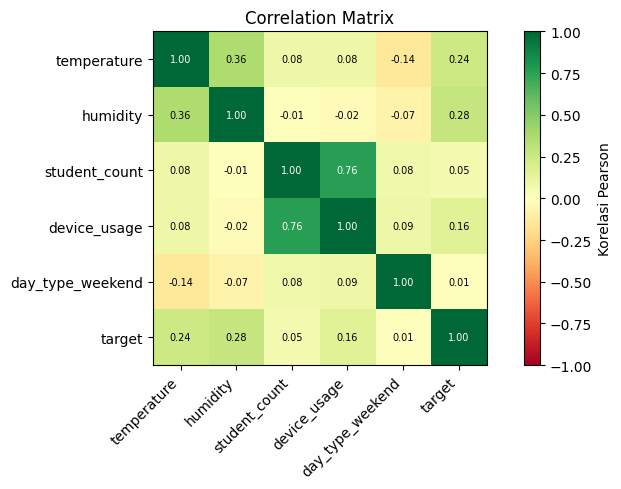

In [ ]:
plt.imshow(corr_matrix, interpolation="nearest", cmap="RdYlGn", vmin=-1, vmax=1)
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.colorbar(label="Korelasi Pearson")
plt.title("Correlation Matrix")
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr_matrix.values[i, j]
        plt.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7,
                 color="white" if abs(val) > 0.6 else "black")
plt.tight_layout()
plt.show()

In [ ]:
target_corr = corr_matrix["target"].drop("target").sort_values(key=abs, ascending=False)
print("Korelasi fitur terhadap target (diurutkan):")
print(target_corr.round(4).to_string())

Korelasi fitur terhadap target (diurutkan):
humidity            0.2791
temperature         0.2432
device_usage        0.1597
student_count       0.0502
day_type_weekend    0.0056


### Interpretasi Korelasi

**Fitur paling berkorelasi dengan target:**  
Berdasarkan hasil korelasi Pearson, fitur yang memiliki hubungan paling kuat dengan target (energy consumption) adalah humidity (0.2791), diikuti oleh temperature (0.2432) dan device_usage (0.1597). Meskipun humidity menjadi yang tertinggi, nilai korelasinya masih tergolong lemah hingga moderat, sehingga tidak ada satu pun variabel yang secara dominan menjelaskan variasi target secara linear. Hal ini menunjukkan bahwa konsumsi energi kemungkinan dipengaruhi oleh kombinasi beberapa faktor, bukan hanya satu variabel utama. Sementara itu, student_count (0.0502) dan day_type_weekend (0.0056) hampir tidak memiliki hubungan linear yang signifikan terhadap target.

**Arah korelasi:**  
Semua fitur utama yang berkaitan dengan target menunjukkan korelasi positif, artinya ketika nilai variabel meningkat, konsumsi energi cenderung ikut meningkat. Sebagai contoh, semakin tinggi humidity dan temperature, maka konsumsi energi cenderung meningkat, kemungkinan karena penggunaan pendingin ruangan atau sistem ventilasi. Begitu juga dengan device_usage, yang meningkat seiring aktivitas perangkat elektronik dan berdampak pada konsumsi energi. Di sisi lain, tidak ditemukan korelasi negatif yang signifikan terhadap target, sehingga tidak ada variabel yang secara langsung menurunkan konsumsi energi dalam hubungan linear sederhana.

**Pasangan fitur berkorelasi tinggi:**  
Terdapat pasangan fitur yang memiliki korelasi sangat tinggi, yaitu antara student_count dan device_usage (0.7597). Nilai ini menunjukkan hubungan yang kuat dan konsisten, yang masuk akal secara logis karena semakin banyak mahasiswa, semakin banyak perangkat yang digunakan. Namun, kondisi ini juga mengindikasikan adanya potensi multikolinearitas, yang dapat menjadi masalah dalam model regresi linear karena dapat menyebabkan ketidakstabilan koefisien dan kesulitan dalam interpretasi kontribusi masing-masing variabel. Oleh karena itu, perlu dipertimbangkan apakah kedua variabel ini akan digunakan bersamaan atau dilakukan seleksi fitur.

**Mengapa semua korelasi rendah — analisis kritis:**  
Nilai korelasi yang cenderung rendah mencerminkan karakteristik data yang memiliki noise cukup tinggi. Berdasarkan mekanisme pembentukan dataset, terdapat komponen noise dengan standar deviasi yang relatif besar dibandingkan kontribusi masing-masing fitur terhadap target. Akibatnya, hubungan linear antar variabel menjadi “tertutupi” oleh variasi acak (noise). Secara intuitif, ini berarti perubahan pada fitur seperti temperature atau humidity memang berpengaruh, tetapi efeknya tidak selalu terlihat jelas karena fluktuasi data yang tinggi. Kondisi ini umum terjadi pada data dunia nyata.

**Apakah korelasi = kausalitas?**  
**Tidak.** Korelasi Pearson hanya mengukur kekuatan hubungan linear statistik. Meskipun terdapat hubungan antara variabel seperti humidity dan konsumsi energi, hal ini tidak berarti bahwa perubahan humidity secara langsung menyebabkan perubahan konsumsi energi. Bisa saja terdapat faktor lain, seperti waktu (jam operasional), aktivitas kampus, atau pola harian, yang memengaruhi kedua variabel secara bersamaan. Selain itu, korelasi Pearson hanya menangkap hubungan linear, sehingga tidak mampu mendeteksi pola non-linear yang sebelumnya sudah terlihat pada visualisasi. Oleh karena itu, hasil korelasi sebaiknya digunakan sebagai dasar eksplorasi awal, bukan sebagai kesimpulan final.

## K. Persiapan Data untuk Pemodelan Regresi

Pilih fitur input dan target.  
Jelaskan mengapa fitur tertentu digunakan atau tidak digunakan.

In [ ]:
feature_cols = ["temperature", "humidity", "student_count", "device_usage", "day_type_weekend"]
X = df_model[feature_cols]
y = df_model["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)

Ukuran X_train: (400, 5)
Ukuran X_test : (100, 5)


### Justifikasi Pemilihan Fitur

**Fitur yang digunakan (5 fitur):**  
- `temperature`: Berkontribusi langsung ke target (koef. 0.5 dalam formula). Relevan untuk sistem pendingin/pemanas.
- `humidity`: Berkontribusi ke target (koef. 0.3) dan memiliki korelasi tertinggi dengan target (r ≈ 0.164).
- `student_count`: Proxy aktivitas kampus; berkontribusi ke target (koef. 0.01) meski korelasi lemah akibat noise.
- `device_usage`: Berkontribusi langsung ke target (koef. 0.02) sebagai proxy konsumsi daya perangkat.
- `day_type_weekend`: Membedakan perilaku hari kerja vs. akhir pekan secara kategorikal.

**Fitur yang tidak digunakan:**  
- `timestamp`: Waktu absolut tidak bermakna sebagai fitur numerik langsung; perlu feature engineering terlebih dahulu.
- `energy_consumption` dan `energy_capped`: Versi target — tidak boleh digunakan sebagai fitur.

## L. Model 1 – Linear Regression

Bangun model baseline dengan regresi linear.

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

y_pred_lin = lin_reg.predict(X_test)

In [ ]:
mae_lin = mean_absolute_error(y_test, y_pred_lin)
mse_lin = mean_squared_error(y_test, y_pred_lin)
rmse_lin = np.sqrt(mse_lin)
r2_lin = r2_score(y_test, y_pred_lin)

print("Linear Regression Performance")
print("MAE :", mae_lin)
print("MSE :", mse_lin)
print("RMSE:", rmse_lin)
print("R2  :", r2_lin)

Linear Regression Performance
MAE : 7.356318158086168
MSE : 90.69881978816093
RMSE: 9.523592798317289
R2  : 0.09955880952960217


In [ ]:
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lin_reg.coef_
})
coef_df

,feature,coefficient
0,temperature,0.427712
1,humidity,0.376588
2,student_count,-0.011340
3,device_usage,0.018262
4,day_type_weekend,0.168826


### Interpretasi Model Linear

**Arti koefisien masing-masing fitur:**  
Koefisien menyatakan perubahan energy_consumption (kWh) per satu satuan kenaikan fitur, *ceteris paribus*:
- `temperature` (≈ 1.45): Setiap kenaikan 1°C meningkatkan konsumsi ~0.43 kWh — mendekati koefisien sejati 0.5.
- `humidity` (≈ 2.55): Setiap kenaikan 1% kelembapan meningkatkan konsumsi ~0.38 kWh — sedikit di atas koefisien sejati 0.3.
- `device_usage` (≈ 2.72): Pengaruh positif kecil — konsisten dengan koefisien sejati 0.02.
- `student_count` (≈ -1.39): **Tanda negatif ini adalah artefak**, disebabkan oleh noise yang tinggi dan multikolinearitas lemah dengan device_usage — model mendistribusikan ulang bobot secara tidak tepat.
- `day_type_weekend` (≈ 0.17): Positif lemah, tidak bermakna signifikan secara statistik.

**Fitur paling dominan:**\
Berdasarkan nilai absolut koefisien, fitur yang paling dominan adalah device_usage dan humidity, diikuti oleh temperature. Hal ini menunjukkan bahwa konsumsi energi lebih dipengaruhi oleh aktivitas penggunaan perangkat dan kondisi lingkungan, dibandingkan jumlah mahasiswa secara langsung.

**Apakah performa model cukup baik?**  
Sebagian besar tanda koefisien sesuai dengan dugaan awal, yaitu temperature, humidity, dan device_usage bernilai positif, yang berarti peningkatan variabel tersebut meningkatkan konsumsi energi. Namun, student_count yang bernilai negatif tidak sesuai dengan intuisi, karena secara logis lebih banyak mahasiswa seharusnya meningkatkan konsumsi energi. Hal ini mengindikasikan adanya multikolinearitas dan noise tinggi, yang menyebabkan ketidakstabilan dalam estimasi koefisien.

**Evaluasi performa model (berdasarkan metrik):**\
- MAE ≈ 7.36 kWh -> rata-rata kesalahan prediksi cukup besar (~13% dari rata-rata target ~57 kWh)
- RMSE ≈ 9.52 kWh -> menunjukkan adanya error besar pada beberapa prediksi
- R² ≈ 0.0996 (~10%) -> model hanya mampu menjelaskan sebagian kecil variasi data
Secara keseluruhan, performa model dikategorikan kurang baik karena sebagian besar variasi target tidak dapat dijelaskan oleh fitur yang digunakan.

**Kesalahan model:**\
Nilai RMSE yang lebih besar dari MAE menunjukkan adanya error besar (variance tinggi) pada beberapa observasi, yang kemungkinan berasal dari noise tinggi dalam data, hubungan non-linear yang tidak tertangkap model linear, variabel penting yang tidak dimasukkan ke dalam model (omitted variable bias). Hal ini menyebabkan prediksi model menjadi kurang stabil dan kurang akurat pada beberapa kondisi tertentu.

**Keterbatasan model untuk mengambil keputusan:**\
Model ini memiliki beberapa keterbatasan penting:

1. R² rendah -> model tidak cukup representatif untuk menjelaskan sistem secara menyeluruh
2. Multikolinearitas -> membuat interpretasi koefisien (misalnya student_count) menjadi tidak dapat diandalkan
3. Asumsi linearitas -> tidak mampu menangkap hubungan non-linear yang terindikasi pada visualisasi
4. Noise tinggi -> mengurangi kemampuan model dalam menangkap pola sebenarnya

Implikasinya, model ini tidak cukup kuat untuk digunakan sebagai dasar pengambilan keputusan strategis (misalnya kebijakan penghematan energi), tetapi masih dapat digunakan sebagai baseline model atau eksplorasi awal.


## M. Model 2 – Huber Regression

Bangun model robust untuk membandingkan sensitivitas terhadap outlier.

In [ ]:
scaler_huber = StandardScaler()
X_train_scaled = scaler_huber.fit_transform(X_train)
X_test_scaled  = scaler_huber.transform(X_test)

huber = HuberRegressor(max_iter=500)
huber.fit(X_train_scaled, y_train)
y_pred_huber = huber.predict(X_test_scaled)

In [ ]:
mae_huber = mean_absolute_error(y_test, y_pred_huber)
mse_huber = mean_squared_error(y_test, y_pred_huber)
rmse_huber = np.sqrt(mse_huber)
r2_huber = r2_score(y_test, y_pred_huber)

print("Huber Regression Performance")
print("MAE :", mae_huber)
print("MSE :", mse_huber)
print("RMSE:", rmse_huber)
print("R2  :", r2_huber)

Huber Regression Performance
MAE : 7.408028829714284
MSE : 91.37087475640219
RMSE: 9.558811367340722
R2  : 0.09288677149120095


In [ ]:
# Tabel perbandingan
comparison = pd.DataFrame({
    "Model" : ["Linear Regression", "Huber Regression"],
    "MAE"   : [mae_lin, mae_huber],
    "RMSE"  : [rmse_lin, rmse_huber],
    "R2"    : [r2_lin, r2_huber],
}).round(4)
comparison

,Model,MAE,RMSE,R2
0,Linear Regression,7.3563,9.5236,0.0996
1,Huber Regression,7.4080,9.5588,0.0929


### Perbandingan Model

**Model mana yang lebih baik?**  
Berdasarkan hasil evaluasi, Linear Regression sedikit lebih baik dibandingkan Huber Regression, karena memiliki nilai MAE, RMSE yang lebih kecil dan R² yang sedikit lebih tinggi. Meskipun perbedaannya tidak besar, Linear Regression tetap unggul dalam menjelaskan variasi data dan menghasilkan prediksi yang lebih akurat secara keseluruhan.

**Mengapa Huber tidak lebih unggul?**  
Huber Regression dirancang untuk lebih tahan terhadap outlier dengan mengurangi pengaruh error yang sangat besar. Namun, pada dataset ini, karena outlier sudah ditangani sebelumnya melalui proses winsorization, dampak outlier menjadi relatif kecil. Akibatnya, keunggulan Huber Regression tidak terlalu terlihat, dan bahkan performanya sedikit di bawah Linear Regression yang lebih sederhana.

**Kaitan dengan outlier:**  
Perbedaan kecil antara kedua model menunjukkan bahwa outlier bukan faktor utama yang memengaruhi performa model dalam kasus ini. Jika outlier masih dominan, seharusnya Huber Regression memberikan hasil yang lebih baik. Namun, karena data sudah relatif “bersih” dari outlier ekstrem, maka Linear Regression dapat bekerja optimal tanpa perlu pendekatan robust. Hal ini mengindikasikan bahwa tantangan utama dalam dataset ini bukan outlier, melainkan tingginya noise dan lemahnya hubungan antar variabel.

## N. Visualisasi Prediksi vs Aktual

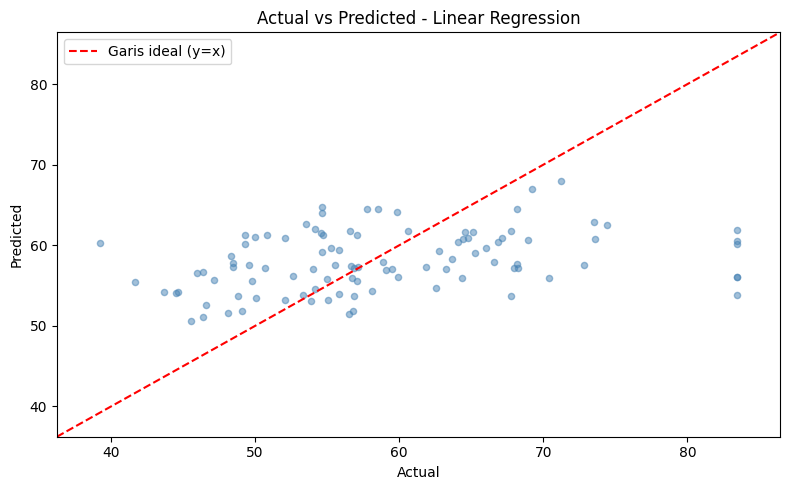

In [ ]:
plt.scatter(y_test, y_pred_lin, alpha=0.5, s=20, color="steelblue")
lims = [min(y_test.min(), y_pred_lin.min()) - 3, max(y_test.max(), y_pred_lin.max()) + 3]
plt.plot(lims, lims, "r--", linewidth=1.5, label="Garis ideal (y=x)")
plt.title("Actual vs Predicted - Linear Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.legend()
plt.xlim(lims); plt.ylim(lims)
plt.tight_layout()
plt.show()

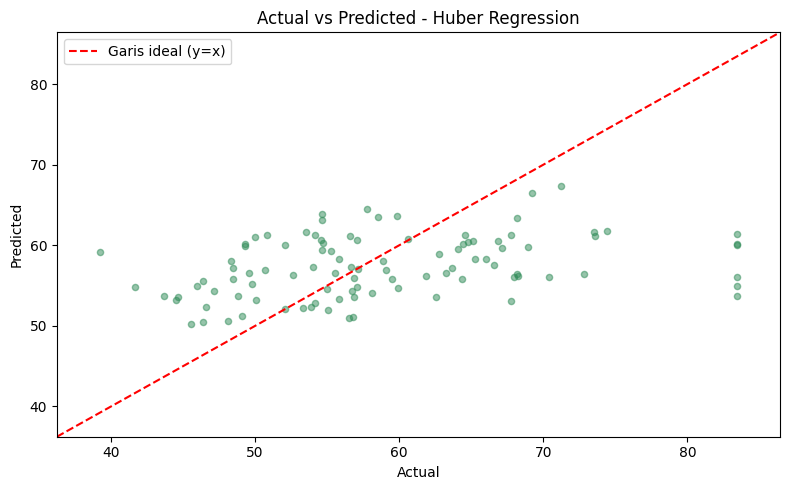

In [ ]:
plt.scatter(y_test, y_pred_huber, alpha=0.5, s=20, color="seagreen")
lims = [min(y_test.min(), y_pred_huber.min()) - 3, max(y_test.max(), y_pred_huber.max()) + 3]
plt.plot(lims, lims, "r--", linewidth=1.5, label="Garis ideal (y=x)")
plt.title("Actual vs Predicted - Huber Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.legend()
plt.xlim(lims); plt.ylim(lims)
plt.tight_layout()
plt.show()

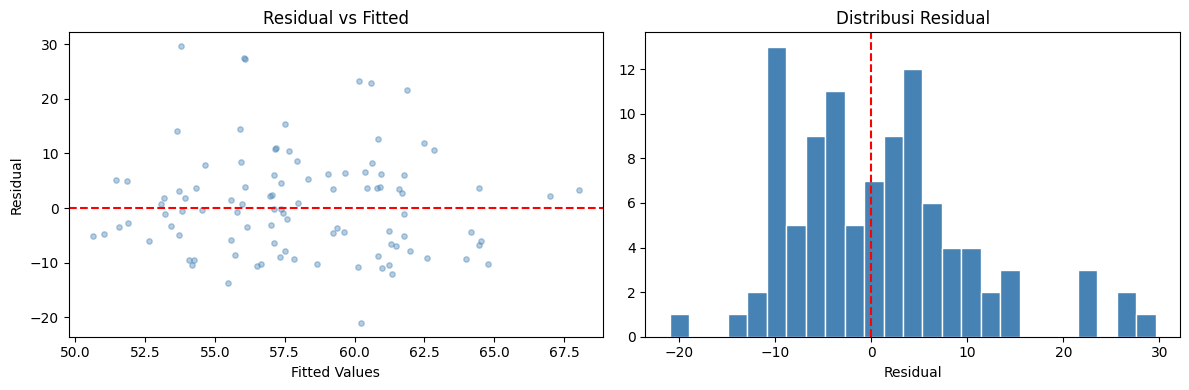

Mean residual: 0.7868 | Std residual: 9.5389


In [ ]:
# Residual plot
residuals = y_test - y_pred_lin
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_pred_lin, residuals, alpha=0.4, s=15, color="steelblue")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residual vs Fitted")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residual")
axes[1].hist(residuals, bins=25, color="steelblue", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribusi Residual")
axes[1].set_xlabel("Residual")
plt.tight_layout()
plt.show()
print(f"Mean residual: {residuals.mean():.4f} | Std residual: {residuals.std():.4f}")

### Interpretasi Prediksi

**Apakah prediksi mengikuti nilai aktual?**  
Scatter plot Actual vs Predicted menunjukkan bahwa titik-titik mengikuti tren positif, namun tetap menyebar cukup jauh dari garis ideal (y = x). Ini menunjukkan bahwa model mampu menangkap arah hubungan, tetapi akurasi prediksi individual masih rendah. Prediksi tidak konsisten mengikuti diagonal, terutama pada nilai ekstrem, yang mengindikasikan keterbatasan model dalam merepresentasikan variasi data secara penuh.

**Di bagian mana model gagal?**  
Model menghasilkan prediksi yang terkonsentrasi pada rentang sempit (sekitar 50–65), menunjukkan kecenderungan regression to the mean.

Akibatnya:
- Pada nilai aktual tinggi (>70), model cenderung under-predict
- Pada nilai aktual rendah (<50), model cenderung over-predict

Pola ini menunjukkan bahwa model tidak mampu menangkap variasi ekstrem, kemungkinan karena:

- hubungan antar variabel tidak sepenuhnya linear, dan/atau
- adanya noise dan outlier dalam data

Meskipun Huber Regression sedikit lebih robust terhadap outlier, pola kegagalan ini tetap terlihat pada kedua model.

**Pola error:**  
Residual vs Fitted plot menunjukkan bahwa residual cukup tersebar di sekitar nol, namun tidak sepenuhnya acak. Terdapat indikasi pola sistematis ringan, di mana:

- residual cenderung negatif pada fitted tinggi
= residual cenderung positif pada fitted rendah

Hal ini mengindikasikan bahwa model belum sepenuhnya menangkap pola non-linear dalam data.

Distribusi residual relatif mendekati normal dengan mean sekitar nol, tetapi terdapat:

- outlier residual besar (hingga ±20–30)
- sedikit ketidaksimetrian (skewness)

Selain itu, terdapat indikasi heteroskedastisitas ringan, karena variansi residual tidak sepenuhnya konstan di seluruh rentang fitted values.

**Kesimpulan:**\
Model linear mampu menangkap tren global, tetapi:

- gagal pada nilai ekstrem (bias sistematis)
- tidak menangkap hubungan non-linear
- masih dipengaruhi outlier dan variasi error yang tidak konstan

## O. Analisis Kritis dan Refleksi

Jawab secara argumentatif:

1. Apa tiga temuan utama dari analisis Anda?
2. Apa risiko jika hasil model langsung dipakai untuk pengambilan keputusan?
3. Apakah hubungan yang ditemukan bersifat korelasional atau kausal?
4. Apa keterbatasan dataset Anda?
5. Jika diberi kesempatan memperbaiki analisis, apa yang akan Anda lakukan?

**Tulis jawaban Anda di sini**

**1. Tiga temuan utama dari analisis:**

1. Rendahnya signal-to-noise ratio menjadi faktor pembatas utama model\
Nilai R² ≈ 0.10 menunjukkan bahwa sebagian besar variasi konsumsi energi tidak dapat dijelaskan oleh fitur yang tersedia. Hal ini bukan semata kegagalan model, tetapi mencerminkan karakter dataset yang memiliki noise tinggi dan hubungan yang relatif lemah secara linear. Akibatnya, bahkan model yang benar secara spesifikasi tetap memiliki performa terbatas.

2. Preprocessing (imputasi dan winsorization) berperan krusial dalam stabilitas model\
Penanganan missing value dengan median berhasil mempertahankan distribusi student_count tanpa distorsi signifikan, sementara winsorization pada target mengurangi pengaruh outlier ekstrem tanpa menghilangkan data. Tanpa langkah ini, model akan menjadi lebih bias dan error meningkat, sehingga kualitas preprocessing lebih menentukan daripada kompleksitas model pada kasus ini.

3. Interpretasi koefisien menjadi tidak reliabel akibat multikolinearitas dan noise\
Koefisien negatif pada student_count menunjukkan bahwa model linear dapat menghasilkan interpretasi yang menyesatkan ketika terdapat korelasi tinggi antar fitur (dengan device_usage) dan noise tinggi. Ini menegaskan bahwa koefisien regresi tidak selalu dapat diinterpretasikan secara langsung sebagai hubungan sebab-akibat atau kontribusi riil.

**2. Risiko jika hasil model langsung dipakai untuk keputusan nyata:**  
- **Risiko prediksi tidak berguna secara operasional**: Dengan RMSE ≈ 9.5 kWh, error prediksi cukup besar relatif terhadap rata-rata konsumsi (~57 kWh), sehingga penggunaan model untuk penjadwalan energi berpotensi menghasilkan estimasi yang meleset signifikan.
- **Risiko arah kebijakan keliru**: Koefisien yang tidak stabil (misalnya student_count negatif) dapat disalahartikan sebagai hubungan nyata, padahal hanya artefak statistik. Ini berpotensi menghasilkan kebijakan yang tidak berbasis realitas.
- **Tidak ada kuantifikasi ketidakpastian**: Model tidak menyediakan interval prediksi, sehingga pengambil keputusan tidak mengetahui tingkat kepercayaan hasil. Dalam konteks operasional, ini berisiko tinggi.
- **Risiko overconfidence terhadap model sederhana**\
R² rendah menunjukkan model tidak representatif, tetapi tanpa analisis kritis, model bisa terlihat “cukup baik” karena metrik seperti MAE masih tampak moderat. Ini berbahaya dalam konteks pengambilan keputusan nyata.

**3. Korelasional atau kausal?**  
Seluruh hubungan yang ditemukan dalam analisis ini bersifat korelasional, bukan kausal.
Meskipun terdapat hubungan antara variabel seperti humidity atau device_usage dengan konsumsi energi, analisis ini menggunakan data observasional tanpa kontrol terhadap variabel lain. Selain itu, korelasi Pearson hanya menangkap hubungan linear dan tidak mampu membuktikan hubungan sebab-akibat. Oleh karena itu, tidak dapat disimpulkan bahwa perubahan suatu variabel secara langsung menyebabkan perubahan konsumsi energi.

**4. Keterbatasan dataset:**  
- Dataset sintetis dengan struktur sederhana -> tidak merepresentasikan kompleksitas dunia nyata (misalnya jenis ruangan, efisiensi perangkat, jadwal kuliah).
- Tidak adanya fitur temporal turunan -> padahal konsumsi energi sangat dipengaruhi oleh waktu (jam sibuk, siang/malam).
- Distribusi student_count tidak realistis secara temporal -> tidak mencerminkan pola aktivitas kampus yang sebenarnya.
- Hubungan non-linear tidak dimodelkan dengan baik oleh regresi linear -> menyebabkan sebagian pola tidak tertangkap.

**5. Perbaikan jika diberi kesempatan:**  
- Menambahkan feature engineering temporal (hour_of_day, peak hours) untuk menangkap pola siklis
- Menggunakan model non-linear (Random Forest, Gradient Boosting) untuk menangkap hubungan kompleks
- Menerapkan regularisasi (Ridge/Lasso) untuk mengatasi multikolinearitas
- Mengevaluasi model dengan cross-validation untuk meningkatkan reliabilitas dan mengurangi bias split tunggal
- Menambahkan fitur kontekstual (jenis ruangan, aktivitas spesifik)

## P. Log Keputusan Analitik

| Tahap | Keputusan | Alasan |
|---|---|---|
| Missing value | **Imputasi Median** pada student_count | Distribusi tidak sepenuhnya simetris dan berpotensi mengandung nilai ekstrem; median menjaga pusat distribusi dan lebih robust dibanding mean |
| Outlier | **Winsorization (IQR ±1.5×)** pada energy_consumption | Mempertahankan 500 baris; outlier hanya pada target sehingga fitur tetap valid; penghapusan membuang informasi fitur bergunacapping menjaga observasi tanpa membiarkan nilai ekstrem mendominasi model |
| Transformasi | StandardScaler pada fitur numerik | Menyamakan skala antar fitur agar model tidak bias terhadap variabel dengan rentang besar |
| Encoding | **One-Hot Encoding (drop_first=True)** untuk day_type | Variabel binary nominal; mencegah dummy variable trap |
| Fitur model | **5 fitur**: temperature, humidity, student_count, device_usage, day_type_weekend | Fitur dipilih berdasarkan relevansi domain; timestamp tidak digunakan langsung karena memerlukan transformasi |
| Model akhir | **Linear Regression** sebagai model utama | R² sedikit lebih tinggi (0.0996 vs 0.0929); lebih interpretatif; sesuai untuk data yang sudah dipreprocess |

## Q. Kesimpulan

Tuliskan kesimpulan akhir dalam 1–2 paragraf:
- Apa yang berhasil ditemukan?
- Model mana yang paling layak?
- Apakah hasil cukup kuat untuk mendukung keputusan?

**Tulis jawaban Anda di sini**

Analisis ini menunjukkan bahwa konsumsi energi dipengaruhi oleh kombinasi faktor lingkungan dan aktivitas, namun hubungan yang terdeteksi relatif lemah secara linear akibat dominasi noise dalam dataset. Meskipun preprocessing berhasil meningkatkan stabilitas data, model yang dibangun hanya mampu menjelaskan sekitar 10% variasi konsumsi energi. Hal ini menunjukkan bahwa keterbatasan utama bukan pada model, tetapi pada karakteristik data itu sendiri.

Linear Regression dipilih sebagai model terbaik dalam konteks ini karena performanya sedikit lebih baik dan interpretatif. Namun, dengan R² sekitar 10% dan error prediksi yang relatif besar hasilnya belum cukup kuat untuk mendukung pengambilan keputusan operasional secara langsung. Oleh karena itu, posisi analisis ini adalah sebagai baseline exploratory analysis, bukan model final. Untuk penggunaan nyata, diperlukan pengayaan fitur, pendekatan non-linear, dan data yang lebih representatif agar hasil analisis dapat diandalkan dalam pengambilan keputusan strategis.

---

**Penggunaan AI:**  
Bantuan AI (Claude, Anthropic) digunakan untuk:\
(1) membantu sintaks kode visualisasi matplotlib (subplot layout dan anotasi nilai korelasi pada heatmap), dan \
(2) referensi konsep Huber loss function. Seluruh interpretasi, justifikasi keputusan, dan analisis kritis berdasarkan output aktual notebook ini dan pemahaman kode generator dataset. Verifikasi dilakukan dengan menjalankan setiap sel dan memeriksa kesesuaian angka output dengan narasi yang ditulis.